# **Task 1 — AI Intelligent System**
Project: Intelligent handwritten digit recognition
- Dataset: Scikit-learn Digits Dataset — 1,797 samples of handwritten digits.
- Model: Multi-Layer Perceptron (MLP) neural network.
- Preprocessing: Feature scaling and train/test splitting.
- Prediction: Recognize digits from 0 to 9.
- Evaluation: Accuracy, precision, recall, F1 score, and confusion matrix.
- Visualization: Sample digit images, confusion matrix, and neural network training-loss curve.
- User interaction: Enter a test-sample number to see the predicted digit and confidence.

AI TASK: INTELLIGENT DIGIT RECOGNITION SYSTEM
---------------------------------------------
Dataset: Scikit-learn Digits Dataset
Total Samples: 1797
Features: 64
Image Size: 8 x 8
Classes: [0 1 2 3 4 5 6 7 8 9]

First 5 Dataset Samples
-----------------------
 Pixel_0  Pixel_1  Pixel_2  Pixel_3  Pixel_4  Pixel_5  Pixel_6  Pixel_7  Pixel_8  Pixel_9  Pixel_10  Pixel_11  Pixel_12  Pixel_13  Pixel_14  Pixel_15  Pixel_16  Pixel_17  Pixel_18  Pixel_19  Pixel_20  Pixel_21  Pixel_22  Pixel_23  Pixel_24  Pixel_25  Pixel_26  Pixel_27  Pixel_28  Pixel_29  Pixel_30  Pixel_31  Pixel_32  Pixel_33  Pixel_34  Pixel_35  Pixel_36  Pixel_37  Pixel_38  Pixel_39  Pixel_40  Pixel_41  Pixel_42  Pixel_43  Pixel_44  Pixel_45  Pixel_46  Pixel_47  Pixel_48  Pixel_49  Pixel_50  Pixel_51  Pixel_52  Pixel_53  Pixel_54  Pixel_55  Pixel_56  Pixel_57  Pixel_58  Pixel_59  Pixel_60  Pixel_61  Pixel_62  Pixel_63  Digit
     0.0      0.0      5.0     13.0      9.0      1.0      0.0      0.0      0.0      0.0      13.0    

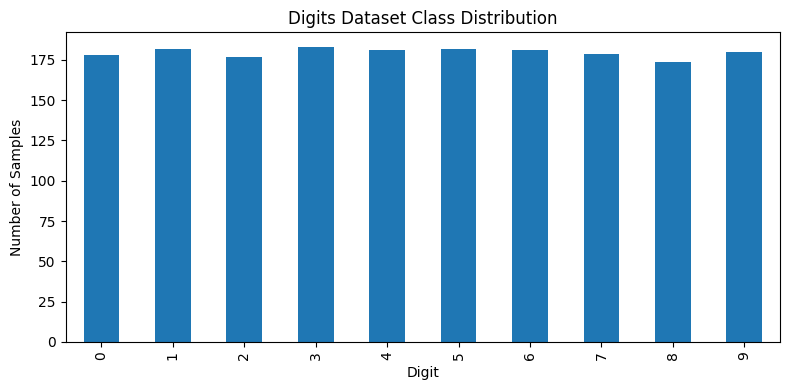

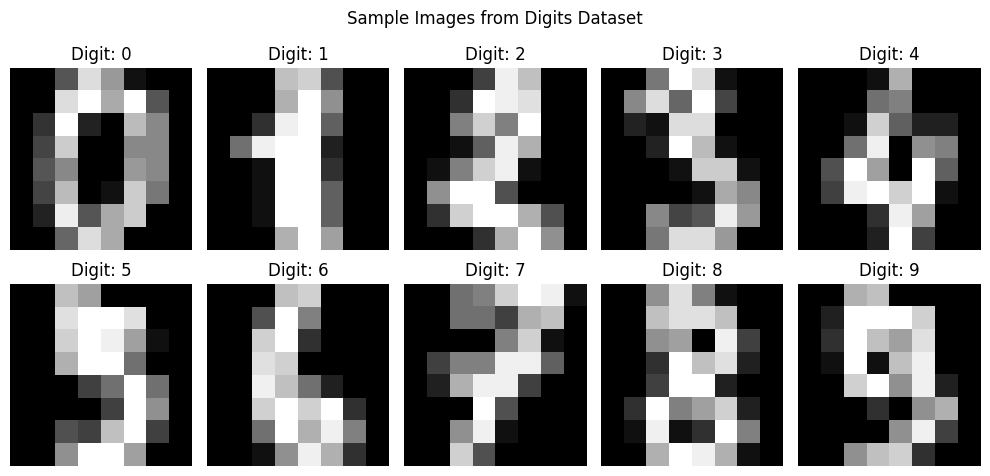


Model: Multi-Layer Perceptron Neural Network
Training Samples: 1437
Testing Samples: 360
Model Training Completed.

Model Performance
-----------------
Accuracy  : 96.11%
Precision : 96.21%
Recall    : 96.11%
F1 Score  : 96.11%

Classification Report
---------------------
              precision    recall  f1-score   support

           0     1.0000    0.9722    0.9859        36
           1     0.8919    0.9167    0.9041        36
           2     0.9211    1.0000    0.9589        35
           3     0.9722    0.9459    0.9589        37
           4     0.9474    1.0000    0.9730        36
           5     0.9737    1.0000    0.9867        37
           6     1.0000    0.9444    0.9714        36
           7     1.0000    1.0000    1.0000        36
           8     0.9118    0.8857    0.8986        35
           9     1.0000    0.9444    0.9714        36

    accuracy                         0.9611       360
   macro avg     0.9618    0.9609    0.9609       360
weighted avg     0.962

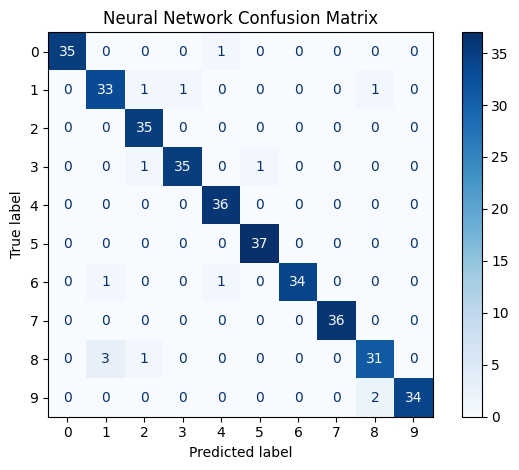

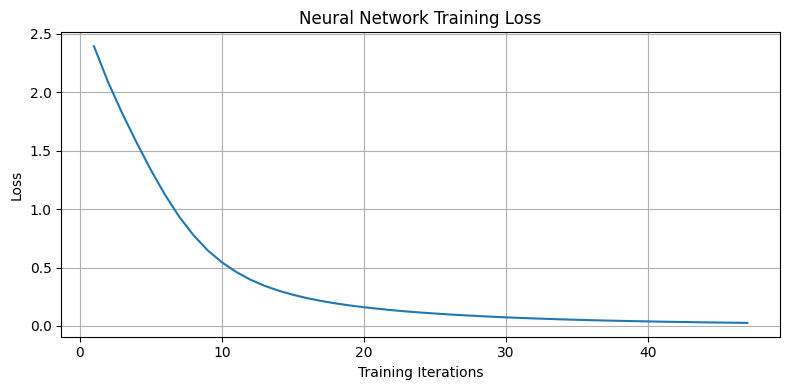


Sample Predictions
------------------
1. Actual: 5 | Predicted: 5
2. Actual: 2 | Predicted: 2
3. Actual: 8 | Predicted: 8
4. Actual: 1 | Predicted: 8
5. Actual: 7 | Predicted: 7

User Interaction
----------------
Enter a test sample number from 1 to 360.
Sample number: 300


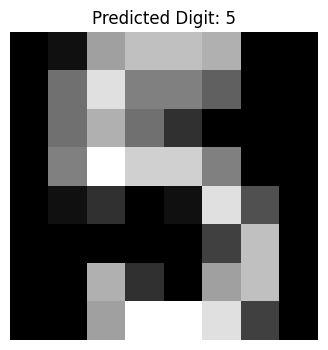

Actual Digit: 5
Predicted Digit: 5
Prediction Confidence: 97.25%

Task 1 Completed.


In [1]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

data = load_digits()

X = data.data
y = data.target

df = pd.DataFrame(X, columns=[f"Pixel_{i}" for i in range(X.shape[1])])
df["Digit"] = y

print("AI TASK: INTELLIGENT DIGIT RECOGNITION SYSTEM")
print("---------------------------------------------")
print("Dataset: Scikit-learn Digits Dataset")
print("Total Samples:", len(X))
print("Features:", X.shape[1])
print("Image Size: 8 x 8")
print("Classes:", np.unique(y))

print("\nFirst 5 Dataset Samples")
print("-----------------------")
print(df.head().to_string(index=False))

print("\nClass Distribution")
print("------------------")
print(df["Digit"].value_counts().sort_index().to_string())

df["Digit"].value_counts().sort_index().plot(
    kind="bar", figsize=(8, 4)
)
plt.title("Digits Dataset Class Distribution")
plt.xlabel("Digit")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(data.images[i], cmap="gray")
    ax.set_title(f"Digit: {y[i]}")
    ax.axis("off")

plt.suptitle("Sample Images from Digits Dataset")
plt.tight_layout()
plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = Pipeline([
    ("scaler", StandardScaler()),
    ("neural_network", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=500,
        early_stopping=True,
        random_state=42
    ))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

print("\nModel: Multi-Layer Perceptron Neural Network")
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Model Training Completed.")

print("\nModel Performance")
print("-----------------")
print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1 Score  : {f1 * 100:.2f}%")

print("\nClassification Report")
print("---------------------")
print(classification_report(y_test, y_pred, digits=4))

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
).plot(cmap="Blues", values_format="d")

plt.title("Neural Network Confusion Matrix")
plt.tight_layout()
plt.show()

loss_values = model.named_steps["neural_network"].loss_curve_

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(loss_values) + 1), loss_values)
plt.title("Neural Network Training Loss")
plt.xlabel("Training Iterations")
plt.ylabel("Loss")
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nSample Predictions")
print("------------------")

for i in range(5):
    print(
        f"{i + 1}. Actual: {y_test[i]} | "
        f"Predicted: {y_pred[i]}"
    )

print("\nUser Interaction")
print("----------------")
print(f"Enter a test sample number from 1 to {len(X_test)}.")

try:
    choice = int(input("Sample number: "))

    if 1 <= choice <= len(X_test):
        index = choice - 1
        sample = X_test[index].reshape(1, -1)
        prediction = model.predict(sample)[0]
        probabilities = model.predict_proba(sample)[0]

        plt.figure(figsize=(4, 4))
        plt.imshow(X_test[index].reshape(8, 8), cmap="gray")
        plt.title(f"Predicted Digit: {prediction}")
        plt.axis("off")
        plt.show()

        print("Actual Digit:", y_test[index])
        print("Predicted Digit:", prediction)
        print(f"Prediction Confidence: {max(probabilities) * 100:.2f}%")
    else:
        print("Invalid selection.")

except ValueError:
    print("Please enter a valid whole number.")

print("\nTask 1 Completed.")


# **Task 2 — ML Prediction System**
Project: California house price prediction
- Dataset: California Housing Dataset from Scikit-learn.
- Models: Linear Regression and Random Forest Regression.
- Preprocessing: Missing-value handling, scaling for Linear Regression, and train/test splitting.
- Model tuning: GridSearchCV with cross-validation.
- Evaluation: R² score, mean absolute error (MAE), and root mean squared error (RMSE).
- Visualization: Model comparison, actual versus predicted prices, and feature importance.
- User interaction: Enter eight housing features to predict an estimated house value.

ML TASK: CALIFORNIA HOUSE PRICE PREDICTION
------------------------------------------
Dataset: California Housing Dataset
Total Samples: 20640
Features: 8
Target: Median House Value (units of $100,000)

First 5 Dataset Samples
-----------------------
 MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  Longitude  HouseValue
 8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88    -122.23       4.526
 8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86    -122.22       3.585
 7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85    -122.24       3.521
 5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85    -122.25       3.413
 3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85    -122.25       3.422

Dataset Summary
---------------
         MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  Longitude  HouseValue
count  20640.00  20640.00  20640.00   20640.00    

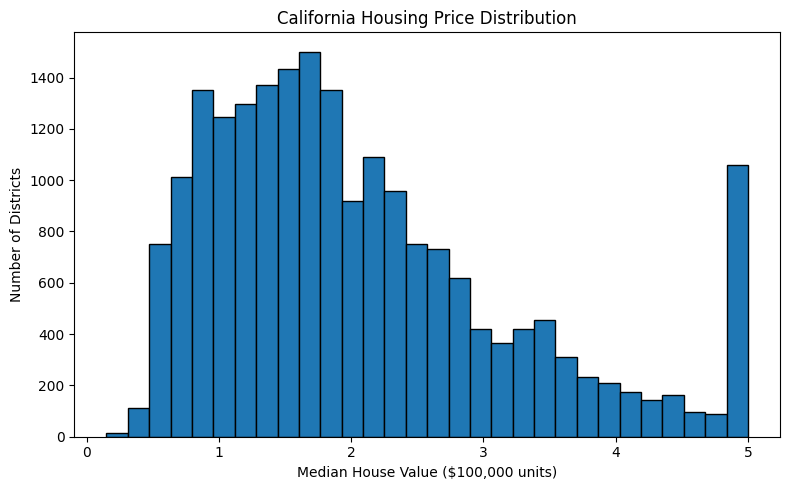


Initial Model Comparison
------------------------
            Model  R2 Score    MAE   RMSE
Linear Regression    0.5758 0.5332 0.7456
    Random Forest    0.8051 0.3275 0.5053


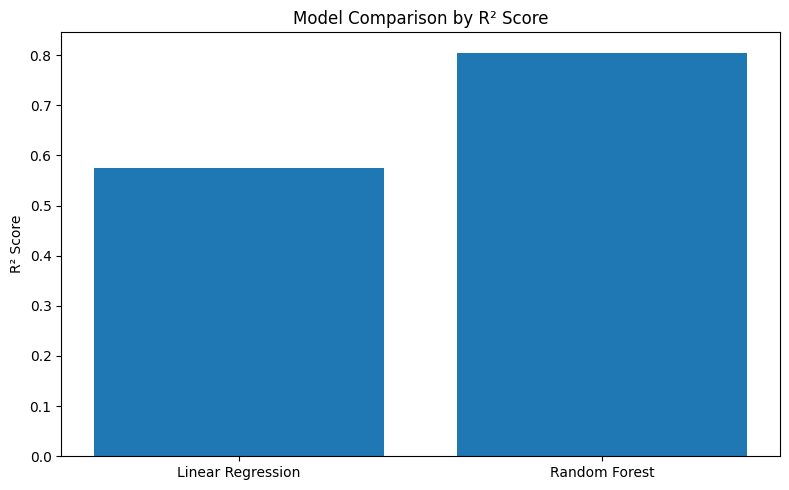

Fitting 3 folds for each of 8 candidates, totalling 24 fits

Tuned Random Forest Model
-------------------------
Best Parameters: {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 120}
Best Cross-Validation R²: 0.8012
Test R² Score: 0.8057
Mean Absolute Error: 0.3266
Root Mean Squared Error: 0.5046


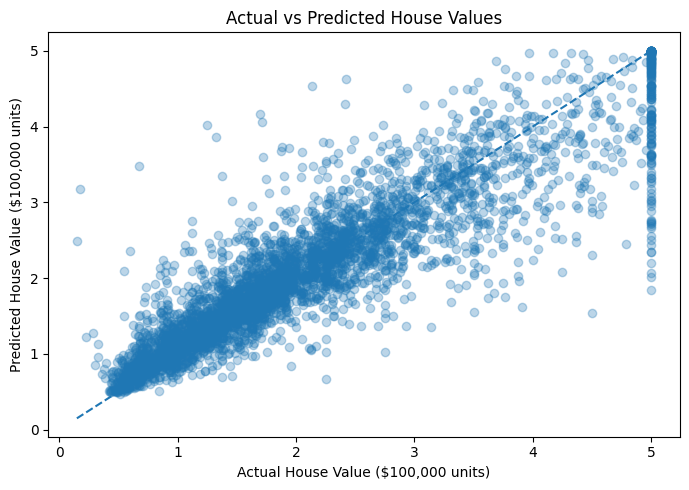

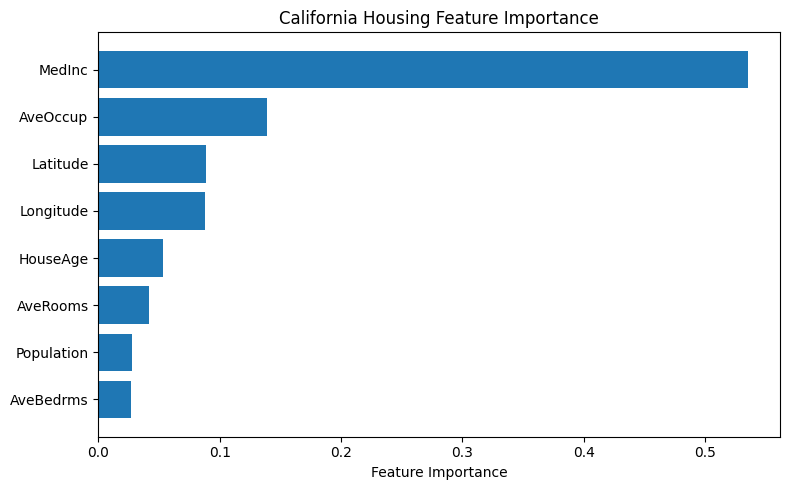


Sample Predictions
------------------
1. Actual: $47,700 | Predicted: $50,128
2. Actual: $45,800 | Predicted: $77,323
3. Actual: $500,001 | Predicted: $488,297
4. Actual: $218,600 | Predicted: $254,309
5. Actual: $278,000 | Predicted: $233,950

User Input House Price Prediction
---------------------------------
Enter 8 values in this exact order:
MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude

Use dataset feature units. Example format: 3.5, 25, 5.2, 1.1, 1200, 3.0, 34.0, -118.0

Enter the 8 values separated by commas: 33,44,55,66,77,11,55,66

Prediction Result
-----------------
Estimated Median House Value: $320,256
This is a model estimate, not a guaranteed selling price.

Task 2 Completed.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but SimpleImputer was fitted without feature names
  warnings.warn(


In [3]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

data = fetch_california_housing()

X = data.data
y = data.target

df = pd.DataFrame(X, columns=data.feature_names)
df["HouseValue"] = y

print("ML TASK: CALIFORNIA HOUSE PRICE PREDICTION")
print("------------------------------------------")
print("Dataset: California Housing Dataset")
print("Total Samples:", len(X))
print("Features:", X.shape[1])
print("Target: Median House Value (units of $100,000)")

print("\nFirst 5 Dataset Samples")
print("-----------------------")
print(df.head().to_string(index=False))

print("\nDataset Summary")
print("---------------")
print(df.describe().round(2).to_string())

plt.figure(figsize=(8, 5))
plt.hist(y, bins=30, edgecolor="black")
plt.title("California Housing Price Distribution")
plt.xlabel("Median House Value ($100,000 units)")
plt.ylabel("Number of Districts")
plt.tight_layout()
plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

linear_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

models = {
    "Linear Regression": linear_model,
    "Random Forest": forest_model
}

results = []
predictions = {}

for name, current_model in models.items():
    current_model.fit(X_train, y_train)
    pred = current_model.predict(X_test)
    predictions[name] = pred

    results.append({
        "Model": name,
        "R2 Score": r2_score(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred))
    })

results_df = pd.DataFrame(results)

print("\nInitial Model Comparison")
print("------------------------")
print(results_df.round(4).to_string(index=False))

plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["R2 Score"])
plt.title("Model Comparison by R² Score")
plt.ylabel("R² Score")
plt.tight_layout()
plt.show()

cv = KFold(n_splits=3, shuffle=True, random_state=42)

tuning_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

parameters = {
    "model__n_estimators": [80, 120],
    "model__max_depth": [None, 20],
    "model__min_samples_leaf": [1, 2]
}

search = GridSearchCV(
    tuning_pipeline,
    parameters,
    cv=cv,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

best_model = search.best_estimator_
y_pred = best_model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("\nTuned Random Forest Model")
print("-------------------------")
print("Best Parameters:", search.best_params_)
print(f"Best Cross-Validation R²: {search.best_score_:.4f}")
print(f"Test R² Score: {r2:.4f}")
print(f"Mean Absolute Error: {mae:.4f}")
print(f"Root Mean Squared Error: {rmse:.4f}")

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.3)
limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]
plt.plot(limits, limits, linestyle="--")
plt.xlabel("Actual House Value ($100,000 units)")
plt.ylabel("Predicted House Value ($100,000 units)")
plt.title("Actual vs Predicted House Values")
plt.tight_layout()
plt.show()

feature_importances = best_model.named_steps["model"].feature_importances_
indices = np.argsort(feature_importances)

plt.figure(figsize=(8, 5))
plt.barh(
    np.array(data.feature_names)[indices],
    feature_importances[indices]
)
plt.xlabel("Feature Importance")
plt.title("California Housing Feature Importance")
plt.tight_layout()
plt.show()

print("\nSample Predictions")
print("------------------")

for i in range(5):
    print(
        f"{i + 1}. Actual: ${y_test[i] * 100000:,.0f} | "
        f"Predicted: ${y_pred[i] * 100000:,.0f}"
    )

print("\nUser Input House Price Prediction")
print("---------------------------------")
print("Enter 8 values in this exact order:")
print(", ".join(data.feature_names))
print("\nUse dataset feature units. Example format: 3.5, 25, 5.2, 1.1, 1200, 3.0, 34.0, -118.0")

user_input = input("\nEnter the 8 values separated by commas: ")

try:
    values = [float(value.strip()) for value in user_input.split(",")]

    if len(values) != len(data.feature_names):
        print(f"Please enter exactly {len(data.feature_names)} values.")
    else:
        sample = pd.DataFrame([values], columns=data.feature_names)
        predicted_value = best_model.predict(sample)[0]

        print("\nPrediction Result")
        print("-----------------")
        print(f"Estimated Median House Value: ${predicted_value * 100000:,.0f}")
        print("This is a model estimate, not a guaranteed selling price.")

except ValueError:
    print("Invalid input. Please enter numerical values separated by commas.")

print("\nTask 2 Completed.")
